In [1]:
import copy
import os
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/mahmoudmohamedm18/new-processed/preprocessed_hourly (1).csv


In [2]:
file_path ="/kaggle/input/datasets/mahmoudmohamedm18/new-processed/preprocessed_hourly (1).csv"

df = pd.read_csv(file_path)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Unique entities: {df['Country code'].nunique()}")
print("\nEntities:")
print(sorted(df["Country code"].dropna().unique()))

Rows: 5,294,364
Columns: 19
Unique entities: 50

Entities:
['ALB', 'AUT', 'BEL', 'BGD', 'BGR', 'BIH', 'CHE', 'CHL', 'COL', 'CRI', 'CYP', 'CZE', 'DEU', 'DNK', 'DZA', 'ESP', 'EST', 'FIN', 'FRA', 'GBR', 'GEO', 'GRC', 'HRV', 'HUN', 'IRL', 'ITA', 'LKA', 'LTU', 'LUX', 'LVA', 'MDA', 'MKD', 'MNE', 'NLD', 'NOR', 'NZL', 'PAN', 'PER', 'PHL', 'POL', 'PRT', 'ROU', 'SGP', 'SRB', 'SVK', 'SVN', 'SWE', 'TWN', 'UKR', 'URY']


In [ ]:
import sys
sys.path.append("/kaggle/input/cb-benchmark")
from cb_benchmark import *

CB["NB"] = "P3"                        # P1 … P7
CB["FE"] = "FE-3a raw load+temp · 60h"      # default feature-set label for this notebook
CB["SEED"] = 42
CB_TABLE = cb_origin_table(df)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5294364 entries, 0 to 5294363
Data columns (total 19 columns):
 #   Column                                     Dtype  
---  ------                                     -----  
 0   Country code                               object 
 1   Hour (UTC)                                 object 
 2   Load_MW_hourly                             float64
 3   Temperature - Top 1 (K)                    float64
 4   Temperature - Top 3 (K)                    float64
 5   hour                                       int64  
 6   month                                      int64  
 7   year                                       int64  
 8   is_weekend                                 int64  
 9   is_holiday                                 int64  
 10  GDP PPP per capita (2021 international $)  float64
 11  Population                                 float64
 12  Past 30-day avg temperature - Top 1 (K)    float64
 13  Past 365-day avg temperature - Top 1 (K)  

In [4]:
df["Hour (UTC)"] = pd.to_datetime(df["Hour (UTC)"])
df["Hour (UTC)"].dtype
df["Hour (UTC)"].min(), df["Hour (UTC)"].max()

(Timestamp('1997-01-01 06:00:00'), Timestamp('2026-09-14 05:00:00'))

In [5]:
df = df.sort_values(["Country code", "Hour (UTC)"]).reset_index(drop=True)

assert not df.duplicated(["Country code", "Hour (UTC)"]).any()
assert (
    df.groupby("Country code")["Hour (UTC)"].diff().dropna() == pd.Timedelta(hours=1)
).all(), "Hourly grid is not contiguous"

print("Rows:", f"{len(df):,}", "| Countries:", df["Country code"].nunique())
print("Load NaN:", f"{df['Load_MW_hourly'].isna().sum():,}")

Rows: 5,294,364 | Countries: 50
Load NaN: 83,770


In [6]:
df["Load_MW_hourly"].describe()

count    5.210594e+06
mean     8.811564e+03
std      1.200052e+04
min      1.018800e+02
25%      1.683330e+03
50%      5.170810e+03
75%      9.122414e+03
max      9.449200e+04
Name: Load_MW_hourly, dtype: float64

In [7]:
df["Load_MW_hourly"].isna().sum()

np.int64(83770)

In [8]:
df["Load_MW_hourly"].isna().mean() * 100

np.float64(1.5822485949209386)

In [9]:
(df["Load_MW_hourly"] < 0).sum()

np.int64(0)

In [10]:
country_stats = (
    df.groupby("Country code")["Load_MW_hourly"]
      .agg(
          mean="mean",
          std="std",
          min="min",
          max="max",
          median="median"
      )
)

country_stats

,mean,std,min,max,median
Country code,,,,,
ALB,720.682683,348.730789,103.000000,1910.000000,761.000000
AUT,6976.674204,1356.731438,2416.000000,11084.000000,6914.400000
BEL,9564.336716,1393.099063,5930.182500,13670.157500,9542.325000
BGD,8700.591593,2834.985055,2298.500000,17144.387500,8312.250000
BGR,4292.382352,876.201650,1803.000000,7790.877560,4176.000000
BIH,1258.642531,305.507134,303.880000,2569.340000,1269.230000
CHE,7095.078611,1031.196419,3417.560000,10437.060000,7076.570000
CHL,6205.192676,2569.818398,1322.200000,13228.025278,5505.830000
COL,7011.050262,1807.062157,2089.924180,12644.212290,6928.601940


In [11]:
country = "DEU"

country_df = (
    df[df["Country code"] == country]
    .sort_values("Hour (UTC)")
)

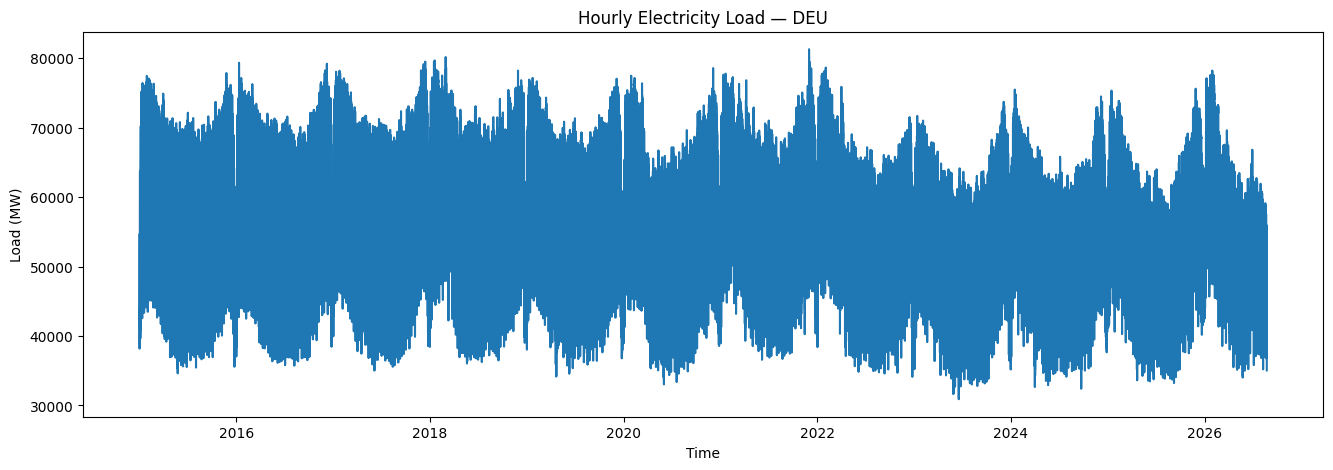

In [12]:
plt.figure(figsize=(16, 5))

plt.plot(
    country_df["Hour (UTC)"],
    country_df["Load_MW_hourly"]
)

plt.xlabel("Time")
plt.ylabel("Load (MW)")
plt.title(f"Hourly Electricity Load — {country}")

plt.show()

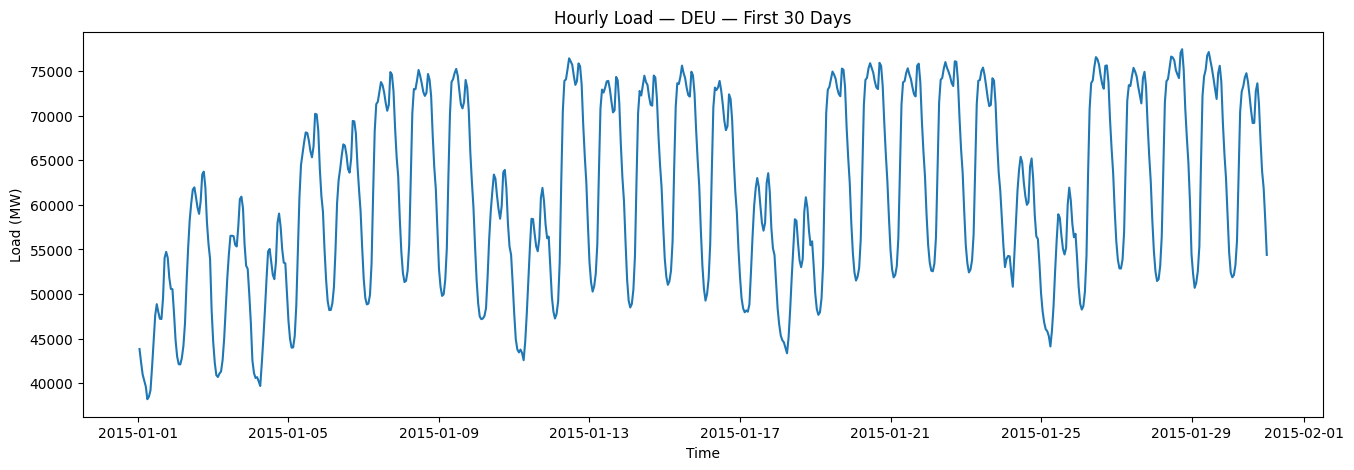

In [13]:
start = country_df["Hour (UTC)"].min()

sample = country_df[
    (country_df["Hour (UTC)"] >= start) &
    (country_df["Hour (UTC)"] < start + pd.Timedelta(days=30))
]

plt.figure(figsize=(16, 5))

plt.plot(
    sample["Hour (UTC)"],
    sample["Load_MW_hourly"]
)

plt.xlabel("Time")
plt.ylabel("Load (MW)")
plt.title(f"Hourly Load — {country} — First 30 Days")

plt.show()

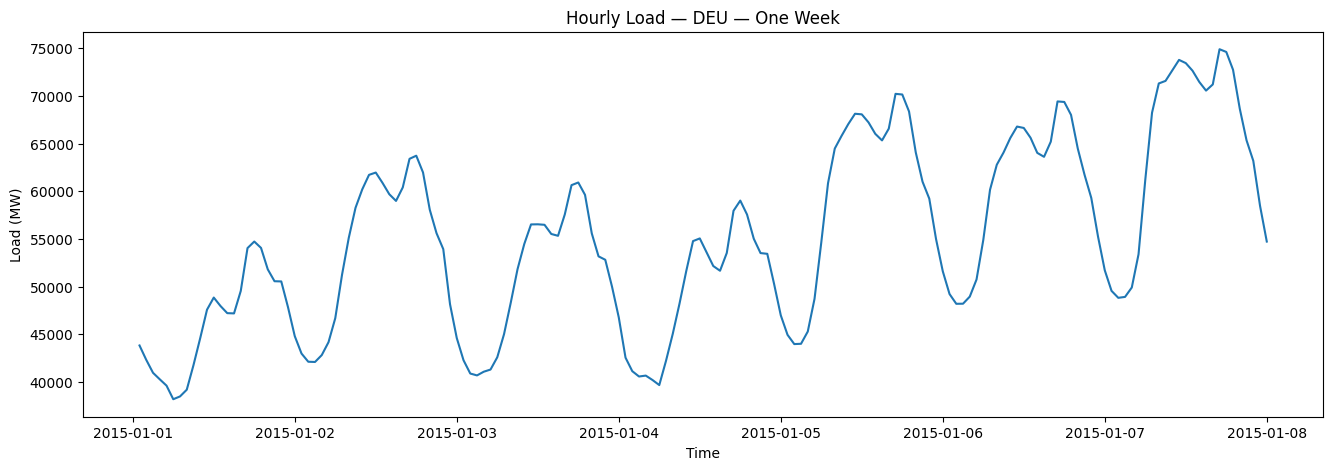

In [14]:
start = country_df["Hour (UTC)"].min()

week = country_df[
    (country_df["Hour (UTC)"] >= start) &
    (country_df["Hour (UTC)"] < start + pd.Timedelta(days=7))
]

plt.figure(figsize=(16, 5))

plt.plot(
    week["Hour (UTC)"],
    week["Load_MW_hourly"]
)

plt.xlabel("Time")
plt.ylabel("Load (MW)")
plt.title(f"Hourly Load — {country} — One Week")

plt.show()

In [15]:
hour_profile = (
    country_df
    .groupby("hour")["Load_MW_hourly"]
    .mean()
)

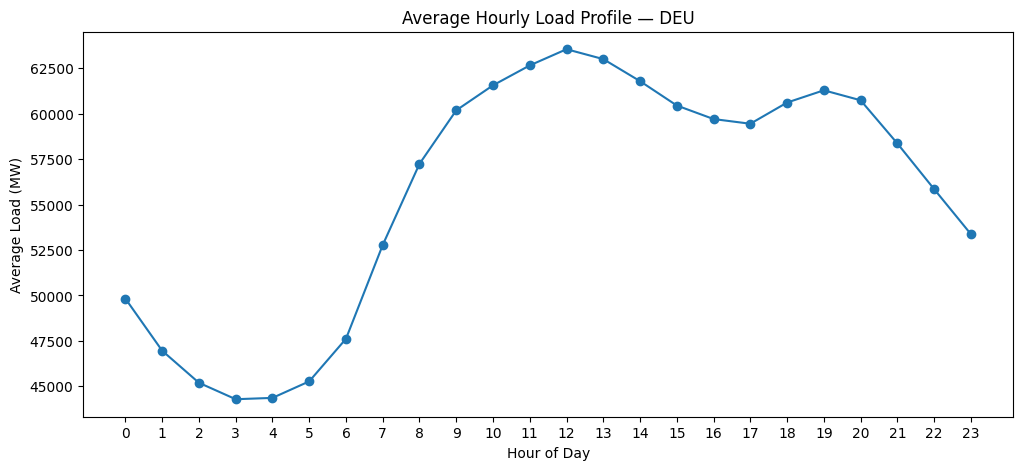

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    hour_profile.index,
    hour_profile.values,
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Load (MW)")
plt.title(f"Average Hourly Load Profile — {country}")

plt.xticks(range(24))

plt.show()

In [17]:
weekend_profile = (
    country_df
    .groupby(["is_weekend", "hour"])["Load_MW_hourly"]
    .mean()
    .reset_index()
)

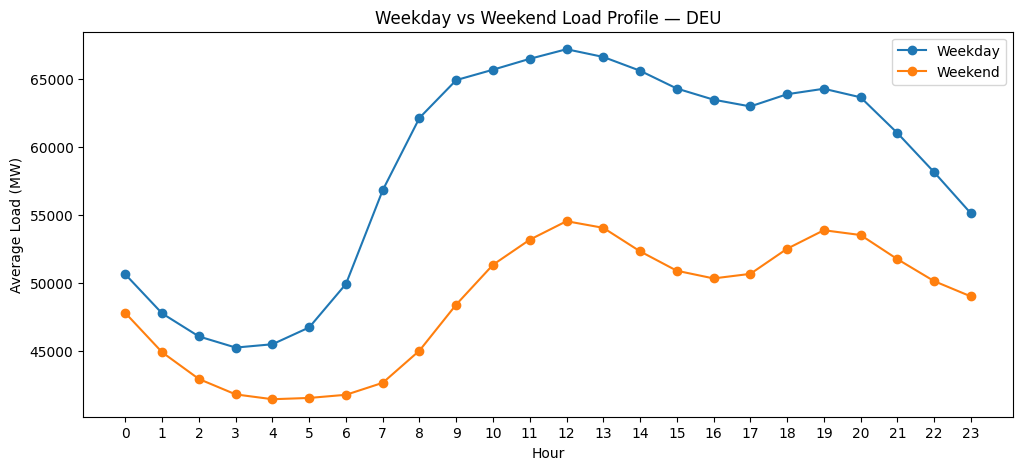

In [18]:
plt.figure(figsize=(12, 5))

for weekend_value in [0, 1]:

    subset = weekend_profile[
        weekend_profile["is_weekend"] == weekend_value
    ]

    plt.plot(
        subset["hour"],
        subset["Load_MW_hourly"],
        marker="o",
        label="Weekend" if weekend_value else "Weekday"
    )

plt.xlabel("Hour")
plt.ylabel("Average Load (MW)")
plt.title(f"Weekday vs Weekend Load Profile — {country}")
plt.xticks(range(24))
plt.legend()

plt.show()

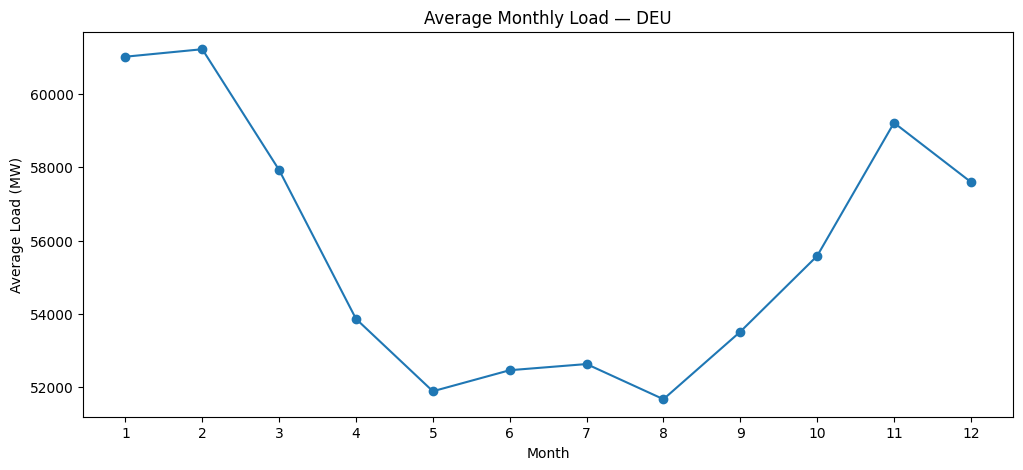

In [19]:
monthly_profile = (
    country_df
    .groupby("month")["Load_MW_hourly"]
    .mean()
)
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_profile.index,
    monthly_profile.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Load (MW)")
plt.title(f"Average Monthly Load — {country}")

plt.xticks(range(1, 13))

plt.show()

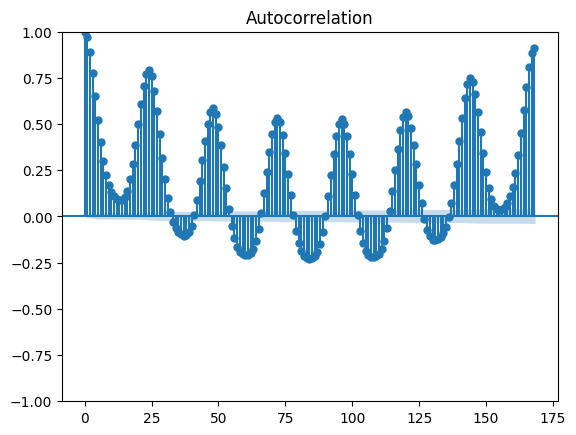

In [20]:
plot_acf(
    country_df["Load_MW_hourly"].dropna(),
    lags=24 * 7
)

plt.show()

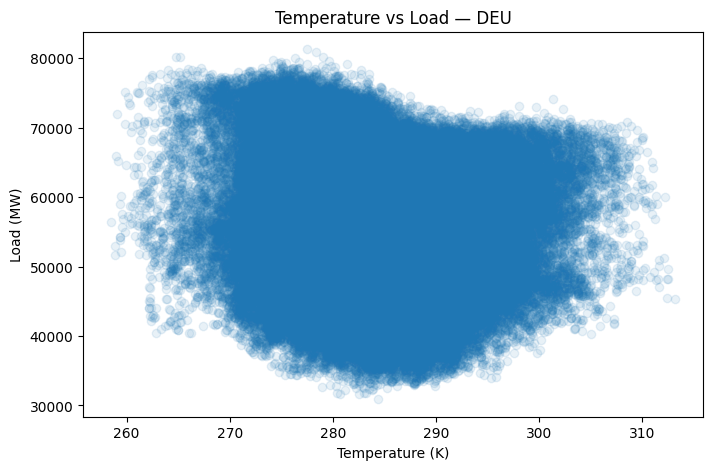

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(
    country_df["Temperature - Top 1 (K)"],
    country_df["Load_MW_hourly"],
    alpha=0.1
)

plt.xlabel("Temperature (K)")
plt.ylabel("Load (MW)")
plt.title(f"Temperature vs Load — {country}")

plt.show()

In [22]:
temperature_columns = [
    "Temperature - Top 1 (K)",
    "Temperature - Top 3 (K)"
]

df[temperature_columns].isna().sum()

temperature_missing_by_country = (
    df.groupby("Country code")[temperature_columns]
      .apply(lambda x: x.isna().sum())
)

temperature_missing_by_country

,Temperature - Top 1 (K),Temperature - Top 3 (K)
Country code,,
ALB,54535,54535
AUT,0,0
BEL,274,274
BGD,1896,1896
BGR,0,0
BIH,606,606
CHE,1609,1609
CHL,6,6
COL,5,5


In [23]:
HISTORY = 60
HORIZON = 24
INPUT_LENGTH = HISTORY

TRAIN_RATIO = 0.8
VALIDATION_RATIO = 0.1

SEED = 42
N_TRAIN = 50000
N_VALIDATION = 10000
EPOCHS = 100
TRAIN_BATCH_SIZE = 32
LEARNING_RATE = 0.0001
DROPOUT = 0.01
HIDDEN_SIZE = 100
D_MODEL = 64

PSO_COUNTRIES = 5
PSO_TRAIN_WINDOWS = 200
PSO_VALIDATION_WINDOWS = 100
PSO_LOOKBACK = 24
PSO_PARTICLES = 8
PSO_ITERATIONS = 8
K_RANGE = (2, 8)
ALPHA_RANGE = (100, 5000)

VMD_TOL = 1e-6
VMD_MAX_ITER = 200
VMD_CHUNK = 512
IMF_SCALER_WINDOWS = 500

TARGET = "Load_MW_hourly"
METEO_COLUMNS = ["Temperature - Top 1 (K)", "Temperature - Top 3 (K)"]
INPUT_COLUMNS = [TARGET] + METEO_COLUMNS
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

np.random.seed(SEED)

In [24]:
country_rows = df.groupby("Country code", sort=False).indices
load_values = df[TARGET].to_numpy()
inputs_observed = df[INPUT_COLUMNS].notna().all(axis=1).to_numpy()

origin_parts = []

for country, rows in country_rows.items():
    cumulative = np.concatenate([[0], np.cumsum(inputs_observed[rows])])

    history_complete = np.zeros(len(rows), dtype=bool)
    history_complete[HISTORY - 1:] = (cumulative[HISTORY:] - cumulative[:-HISTORY]) == HISTORY

    finite = np.isfinite(load_values[rows]).astype(int)
    cf = np.concatenate([[0], np.cumsum(finite)])
    target_available = np.zeros(len(rows), dtype=bool)
    target_available[:-HORIZON] = (cf[1 + HORIZON:] - cf[1:-HORIZON]) == HORIZON

    valid = history_complete & target_available
    origin_parts.append(pd.DataFrame({"Country code": country, "row": rows[valid]}))

valid_origins = pd.concat(origin_parts, ignore_index=True)
valid_origins["Hour (UTC)"] = df["Hour (UTC)"].to_numpy()[valid_origins["row"].to_numpy()]

print("Valid origins:", f"{len(valid_origins):,}")
print("Countries with valid origins:", valid_origins["Country code"].nunique())

Valid origins: 5,078,359
Countries with valid origins: 50


In [25]:
valid_origins = cb_apply_split(valid_origins, CB_TABLE)


split
train         3656445
test          1015654
validation     406260
Name: count, dtype: int64


In [26]:
pd.crosstab(valid_origins["Country code"], valid_origins["split"])

split,test,train,validation
Country code,,,
ALB,8194,29501,3278
AUT,20483,73741,8194
BEL,20488,73760,8196
BGD,21053,75791,8421
BGR,20372,73341,8149
BIH,11153,40152,4461
CHE,20342,73234,8137
CHL,47488,170960,18996
COL,46741,168268,18696


In [27]:
train_origins = valid_origins[valid_origins["split"] == "train"]

country_target_scalers = {
    country: MinMaxScaler().fit(load_values[group["row"].to_numpy()].reshape(-1, 1))
    for country, group in train_origins.groupby("Country code")
}

meteo_values = df[METEO_COLUMNS].to_numpy(dtype=np.float64)
meteo_scaler = MinMaxScaler().fit(meteo_values[train_origins["row"].to_numpy()])

scaled_y = np.full(len(df), np.nan, dtype=np.float32)

for country, rows in country_rows.items():
    if country not in country_target_scalers:
        continue

    observed = np.isfinite(load_values[rows])
    scaled_y[rows[observed]] = country_target_scalers[country].transform(
        load_values[rows[observed]].reshape(-1, 1)
    ).ravel()

scaled_meteo = meteo_scaler.transform(meteo_values).astype(np.float32)

assert meteo_scaler.n_samples_seen_ == len(train_origins)

print("Scaled with training-origin statistics only")
print("Countries:", len(country_target_scalers))

Scaled with training-origin statistics only
Countries: 50


In [28]:
def vmd_batch(signals, k, alpha, tol=VMD_TOL, max_iter=VMD_MAX_ITER):
    signals = np.asarray(signals, dtype=np.float64)
    batch, length = signals.shape

    if length % 2:
        signals = np.concatenate([signals, signals[:, -1:]], axis=1)

    half = signals.shape[1] // 2
    mirrored = np.concatenate(
        [signals[:, :half][:, ::-1], signals, signals[:, -half:][:, ::-1]],
        axis=1
    )
    size = mirrored.shape[1]
    positive = (np.arange(size) / size - 0.5)[size // 2:]

    f_hat = np.fft.fftshift(np.fft.fft(mirrored, axis=1), axes=1)[:, size // 2:]

    u_hat = np.zeros((batch, k, size // 2), dtype=complex)
    omega = np.tile(0.5 / k * np.arange(k), (batch, 1))
    total = np.zeros((batch, size // 2), dtype=complex)
    active = np.ones(batch, dtype=bool)

    for _ in range(max_iter):
        change = np.zeros(batch)

        for i in range(k):
            updated = (f_hat - (total - u_hat[:, i])) / (1 + alpha * (positive[None, :] - omega[:, i:i + 1]) ** 2)
            power = np.abs(updated) ** 2
            new_omega = (positive[None, :] * power).sum(axis=1) / power.sum(axis=1)
            delta = updated - u_hat[:, i]
            change += (np.abs(delta) ** 2).sum(axis=1) / size

            omega[:, i] = np.where(active, new_omega, omega[:, i])
            total += np.where(active[:, None], delta, 0)
            u_hat[:, i] = np.where(active[:, None], updated, u_hat[:, i])

        active &= change >= tol

        if not active.any():
            break

    full = np.zeros((batch, k, size), dtype=complex)
    full[:, :, size // 2:] = u_hat
    full[:, :, size // 2:0:-1] = np.conj(u_hat)
    full[:, :, 0] = np.conj(full[:, :, -1])

    modes = np.real(np.fft.ifft(np.fft.ifftshift(full, axes=2), axis=2))
    return modes[:, :, size // 4:3 * size // 4][:, :, :length]

def decompose(windows, k, alpha):
    chunks = [windows[i:i + VMD_CHUNK] for i in range(0, len(windows), VMD_CHUNK)]

    with ThreadPoolExecutor(max_workers=os.cpu_count()) as pool:
        parts = list(pool.map(lambda chunk: vmd_batch(chunk, k, alpha), chunks))

    return np.concatenate(parts).transpose(0, 2, 1).astype(np.float32)

def pso(fitness, bounds, n_particles, n_iterations):
    rng = np.random.default_rng(SEED)
    low, high = bounds[:, 0], bounds[:, 1]

    position = rng.uniform(low, high, (n_particles, len(low)))
    velocity = np.zeros_like(position)
    personal_best = position.copy()
    personal_score = np.array([fitness(p) for p in position])
    global_best = personal_best[personal_score.argmin()].copy()

    for _ in range(n_iterations):
        r1 = rng.random(position.shape)
        r2 = rng.random(position.shape)
        velocity = 0.7 * velocity + 1.5 * r1 * (personal_best - position) + 1.5 * r2 * (global_best - position)
        position = np.clip(position + velocity, low, high)

        score = np.array([fitness(p) for p in position])
        improved = score < personal_score
        personal_best[improved] = position[improved]
        personal_score[improved] = score[improved]
        global_best = personal_best[personal_score.argmin()].copy()

    return global_best, personal_score.min()

In [29]:
offsets = np.arange(-HISTORY + 1, 1)

def history_index(rows):
    return rows[:, None] + offsets[None, :]

pso_rng = np.random.default_rng(SEED)
pso_countries = train_origins["Country code"].value_counts().head(PSO_COUNTRIES).index

def sample_rows(split, per_country):
    parts = []

    for country in pso_countries:
        rows = valid_origins.loc[
            (valid_origins["Country code"] == country) & (valid_origins["split"] == split),
            "row"
        ].to_numpy()
        parts.append(pso_rng.choice(rows, min(per_country, len(rows)), replace=False))

    return np.concatenate(parts)

pso_train_rows = sample_rows("train", PSO_TRAIN_WINDOWS)
pso_validation_rows = sample_rows("validation", PSO_VALIDATION_WINDOWS)

pso_train_windows = scaled_y[history_index(pso_train_rows)].astype(np.float64)
pso_validation_windows = scaled_y[history_index(pso_validation_rows)].astype(np.float64)
pso_train_target = scaled_y[pso_train_rows + HORIZON]
pso_validation_target = scaled_y[pso_validation_rows + HORIZON]

def pso_features(windows, k, alpha):
    return decompose(windows, k, alpha)[:, -PSO_LOOKBACK:, :].reshape(len(windows), -1)

def vmd_fitness(params):
    k = int(round(params[0]))
    model = Ridge(alpha=1.0).fit(pso_features(pso_train_windows, k, params[1]), pso_train_target)
    predicted = model.predict(pso_features(pso_validation_windows, k, params[1]))

    return mean_squared_error(pso_validation_target, predicted)

best_params, best_mse = pso(
    vmd_fitness,
    np.array([K_RANGE, ALPHA_RANGE], dtype=float),
    PSO_PARTICLES,
    PSO_ITERATIONS
)

K = int(round(best_params[0]))
ALPHA = float(best_params[1])

print("Reference countries:", list(pso_countries))
print("Best k:", K)
print(f"Best alpha: {ALPHA:.2f}")
print(f"Best validation MSE: {best_mse:.6f}")

Reference countries: ['PER', 'CHL', 'COL', 'NZL', 'CYP']
Best k: 4
Best alpha: 100.00
Best validation MSE: 0.000945


In [30]:
rng = np.random.default_rng(SEED)

imf_scalers = {}

for country, group in train_origins.groupby("Country code"):
    rows = rng.choice(group["row"].to_numpy(), min(IMF_SCALER_WINDOWS, len(group)), replace=False)
    components = decompose(scaled_y[history_index(rows)], K, ALPHA)
    imf_scalers[country] = MinMaxScaler().fit(components.reshape(-1, K))

def scale_components(components, countries):
    scaled = np.empty_like(components)

    for country in np.unique(countries):
        mask = countries == country
        part = components[mask]
        scaled[mask] = imf_scalers[country].transform(part.reshape(-1, K)).reshape(part.shape)

    return scaled

def build_windows(sample, with_labels):
    rows = sample["row"].to_numpy()
    countries = sample["Country code"].to_numpy()
    index = history_index(rows)

    window_y = scaled_y[index]
    meteo = scaled_meteo[index]
    load_target = scaled_y[rows[:, None] + np.arange(1, HORIZON + 1)[None, :]]

    raw = np.concatenate([window_y[:, :, None], meteo], axis=2)
    components = scale_components(decompose(window_y, K, ALPHA), countries)
    combined = np.concatenate([components, meteo], axis=2)

    if not with_labels:
        return raw, combined, load_target, None

    extended = np.concatenate([window_y, load_target], axis=1)
    component_target = scale_components(decompose(extended, K, ALPHA)[:, -HORIZON:, :], countries).reshape(len(rows), -1)

    return raw, combined, load_target, component_target

def to_tensor(array):
    assert np.isfinite(array).all()
    return torch.tensor(array, dtype=torch.float32, device=DEVICE)

train_sample = valid_origins[valid_origins["split"] == "train"].sample(
    min(N_TRAIN, int((valid_origins["split"] == "train").sum())), random_state=SEED
)
validation_sample = valid_origins[valid_origins["split"] == "validation"].sample(
    min(N_VALIDATION, int((valid_origins["split"] == "validation").sum())), random_state=SEED
)
test_sample = valid_origins[valid_origins["split"] == "test"]

train_raw, train_vmd, y_train_load, y_train_imf = build_windows(train_sample, with_labels=True)
validation_raw, validation_vmd, y_validation_load, y_validation_imf = build_windows(validation_sample, with_labels=True)
test_raw, test_vmd, y_test_load, _ = build_windows(test_sample, with_labels=False)

test_country_codes = test_sample["Country code"].to_numpy()

inputs = {
    "raw": tuple(to_tensor(a) for a in (train_raw, validation_raw, test_raw)),
    "vmd": tuple(to_tensor(a) for a in (train_vmd, validation_vmd, test_vmd))
}

targets = {
    "raw": (to_tensor(y_train_load), to_tensor(y_validation_load)),
    "vmd": (to_tensor(y_train_imf), to_tensor(y_validation_imf))
}

print("Raw input:", train_raw.shape, "| VMD input:", train_vmd.shape)
print("Train:", len(train_sample), "Validation:", len(validation_sample), "Test:", len(test_sample))

Raw input: (50000, 60, 3) | VMD input: (50000, 60, 6)
Train: 50000 Validation: 10000 Test: 1015654


In [31]:
for sample in (train_sample, validation_sample, test_sample):
    rows = sample["row"].to_numpy()
    assert (history_index(rows).max(axis=1) == rows).all()
    assert (valid_origins.loc[sample.index, "row"].to_numpy() == rows).all()

for country, scaler in country_target_scalers.items():
    assert scaler.n_samples_seen_ == int((train_origins["Country code"] == country).sum())

label_error = []

for country in np.unique(train_sample["Country code"]):
    mask = (train_sample["Country code"] == country).to_numpy()
    components = imf_scalers[country].inverse_transform(y_train_imf[mask].reshape(-1, K)).reshape(-1, HORIZON, K)
    label_error.append(np.abs(components.sum(axis=2) - y_train_load[mask]))

print("Split boundaries are chronological per country; inputs end at the origin hour")
print("Target scalers fitted on training origins only")
print("Mean |sum of component labels - load| (scaled):", np.concatenate(label_error).mean())

Split boundaries are chronological per country; inputs end at the origin hour
Target scalers fitted on training origins only
Mean |sum of component labels - load| (scaled): 0.003961221


In [32]:
class BP(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(INPUT_LENGTH * input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, output_size)
        )

    def forward(self, x):
        return self.network(x)

class Recurrent(nn.Module):
    def __init__(self, input_size, rnn, use_cnn=False):
        super().__init__()
        self.use_cnn = use_cnn

        if use_cnn:
            self.cnn = nn.Sequential(
                nn.Conv1d(input_size, 64, 5, padding=2),
                nn.ReLU(),
                nn.Conv1d(64, 128, 3, padding=1),
                nn.ReLU(),
                nn.MaxPool1d(2)
            )
            input_size = 128

        self.rnn = rnn(input_size, HIDDEN_SIZE, batch_first=True)
        self.output = nn.Linear(HIDDEN_SIZE, HORIZON)

    def forward(self, x):
        if self.use_cnn:
            x = self.cnn(x.transpose(1, 2)).transpose(1, 2)

        out, _ = self.rnn(x)
        return self.output(out[:, -1])

class TransformerNet(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.embed = nn.Linear(input_size, D_MODEL)
        self.position = nn.Parameter(torch.zeros(1, INPUT_LENGTH, D_MODEL))
        layer = nn.TransformerEncoderLayer(D_MODEL, 4, 128, DROPOUT, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)
        self.output = nn.Linear(D_MODEL, HORIZON)

    def forward(self, x):
        x = self.encoder(self.embed(x) + self.position)
        return self.output(x.mean(dim=1))

class VCAG(nn.Module):
    def __init__(self, input_size, output_size, use_attention=True):
        super().__init__()
        self.use_attention = use_attention

        self.cnn = nn.Sequential(
            nn.Conv1d(input_size, 64, 5, padding=2),
            nn.ReLU(),
            nn.Conv1d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )
        self.attention = nn.Linear(128, 1)
        self.gru1 = nn.GRU(128, 100, batch_first=True, bidirectional=True)
        self.gru2 = nn.GRU(200, 200, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(DROPOUT)
        self.fc = nn.Sequential(
            nn.Linear(400, 25),
            nn.ReLU(),
            nn.Linear(25, output_size)
        )

    def forward(self, x):
        x = self.cnn(x.transpose(1, 2)).transpose(1, 2)

        if self.use_attention:
            weights = torch.softmax(self.attention(x), dim=1)
            x = x * weights * x.size(1)

        x, _ = self.gru1(x)
        x, _ = self.gru2(self.dropout(x))
        return self.fc(self.dropout(x[:, -1]))

@torch.no_grad()
def predict(model, X):
    model.eval()
    return torch.cat([model(X[i:i + 8192]) for i in range(0, len(X), 8192)])

def fit_model(model, X, y, X_validation, y_validation):
    torch.manual_seed(SEED)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()

    best_loss = float("inf")
    best_state = None

    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(len(X), device=DEVICE)

        for start in range(0, len(X), TRAIN_BATCH_SIZE):
            batch = order[start:start + TRAIN_BATCH_SIZE]
            optimizer.zero_grad()
            loss = criterion(model(X[batch]), y[batch])
            loss.backward()
            optimizer.step()

        validation_loss = criterion(predict(model, X_validation), y_validation).item()

        if validation_loss < best_loss:
            best_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch + 1}/{EPOCHS} validation loss: {validation_loss:.6f}")

    model.load_state_dict(best_state)
    return model

def to_mw(scaled, countries):
    mw = np.empty(len(scaled), dtype=np.float64)

    for country in np.unique(countries):
        mask = countries == country
        mw[mask] = country_target_scalers[country].inverse_transform(
            scaled[mask].reshape(-1, 1)
        ).ravel()

    return mw

def reconstruct(component_predictions, countries):
    p = component_predictions.reshape(len(countries), HORIZON, K)
    out = np.empty((len(countries), HORIZON))
    for c in np.unique(countries):
        m = countries == c
        out[m] = imf_scalers[c].inverse_transform(p[m].reshape(-1, K)).reshape(-1, HORIZON, K).sum(axis=2)
    return out

def compute_metrics(scaled_actual, scaled_predicted, countries):
    actual = to_mw(scaled_actual, countries)
    predicted = to_mw(scaled_predicted, countries)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": np.mean([
            r2_score(actual[countries == c], predicted[countries == c])
            for c in np.unique(countries)
        ])
    }

results = []

def run_model(name, build_model, use_vmd=False):
    kind = "vmd" if use_vmd else "raw"
    X_train, X_validation, X_test = inputs[kind]
    y_train, y_validation = targets[kind]

    model = fit_model(build_model(X_train.shape[2], y_train.shape[1]), X_train, y_train, X_validation, y_validation)
    predicted = predict(model, X_test).cpu().numpy()

    if use_vmd:
        scaled_load = reconstruct(predicted, test_country_codes)
    else:
        scaled_load = predicted

    row = {"Model": name, **compute_metrics(y_test_load.ravel(), scaled_load.ravel(), np.repeat(test_country_codes, HORIZON))}
    cb_save(name, test_country_codes, test_sample["Hour (UTC)"],
            cb_to_mw(scaled_load, test_country_codes, country_target_scalers),
            feature_set="FE-3b VMD K4 · 60h" if use_vmd else "FE-3a raw load+temp · 60h")
    results.append(row)
    print(pd.Series(row).to_string())

In [33]:
run_model("LSTM", lambda features, outputs: Recurrent(features, nn.LSTM))

Epoch 5/100 validation loss: 0.001449
Epoch 10/100 validation loss: 0.000739
Epoch 15/100 validation loss: 0.000676
Epoch 20/100 validation loss: 0.000593
Epoch 25/100 validation loss: 0.000623
Epoch 30/100 validation loss: 0.000595
Epoch 35/100 validation loss: 0.000569
Epoch 40/100 validation loss: 0.000556
Epoch 45/100 validation loss: 0.000535
Epoch 50/100 validation loss: 0.000514
Epoch 55/100 validation loss: 0.000492
Epoch 60/100 validation loss: 0.000547
Epoch 65/100 validation loss: 0.000502
Epoch 70/100 validation loss: 0.000459
Epoch 75/100 validation loss: 0.000517
Epoch 80/100 validation loss: 0.000443
Epoch 85/100 validation loss: 0.000439
Epoch 90/100 validation loss: 0.000437
Epoch 95/100 validation loss: 0.000433
Epoch 100/100 validation loss: 0.000436
Model          LSTM
MAE      115.207547
RMSE     250.711451
R2         0.983275


In [34]:
run_model("GRU", lambda features, outputs: Recurrent(features, nn.GRU))

Epoch 5/100 validation loss: 0.001138
Epoch 10/100 validation loss: 0.000965
Epoch 15/100 validation loss: 0.000767
Epoch 20/100 validation loss: 0.000725
Epoch 25/100 validation loss: 0.000697
Epoch 30/100 validation loss: 0.000632
Epoch 35/100 validation loss: 0.000618
Epoch 40/100 validation loss: 0.000629
Epoch 45/100 validation loss: 0.000598
Epoch 50/100 validation loss: 0.000575
Epoch 55/100 validation loss: 0.000571
Epoch 60/100 validation loss: 0.000558
Epoch 65/100 validation loss: 0.000583
Epoch 70/100 validation loss: 0.000509
Epoch 75/100 validation loss: 0.000540
Epoch 80/100 validation loss: 0.000497
Epoch 85/100 validation loss: 0.000471
Epoch 90/100 validation loss: 0.000476
Epoch 95/100 validation loss: 0.000472
Epoch 100/100 validation loss: 0.000468
Model           GRU
MAE      117.188321
RMSE     253.507096
R2          0.98279


In [35]:
run_model("BERT", lambda features, outputs: TransformerNet(features))

Epoch 5/100 validation loss: 0.000632
Epoch 10/100 validation loss: 0.000621
Epoch 15/100 validation loss: 0.000442
Epoch 20/100 validation loss: 0.000424
Epoch 25/100 validation loss: 0.000651
Epoch 30/100 validation loss: 0.000409
Epoch 35/100 validation loss: 0.000411
Epoch 40/100 validation loss: 0.000383
Epoch 45/100 validation loss: 0.000386
Epoch 50/100 validation loss: 0.000379
Epoch 55/100 validation loss: 0.000395
Epoch 60/100 validation loss: 0.000409
Epoch 65/100 validation loss: 0.000399
Epoch 70/100 validation loss: 0.000391
Epoch 75/100 validation loss: 0.000390
Epoch 80/100 validation loss: 0.000392
Epoch 85/100 validation loss: 0.000474
Epoch 90/100 validation loss: 0.000400
Epoch 95/100 validation loss: 0.000370
Epoch 100/100 validation loss: 0.000415
Model          BERT
MAE       113.20729
RMSE     237.958071
R2         0.982202


In [36]:
run_model("BP", lambda features, outputs: BP(features, outputs))

Epoch 5/100 validation loss: 0.000866
Epoch 10/100 validation loss: 0.000555
Epoch 15/100 validation loss: 0.000646
Epoch 20/100 validation loss: 0.000441
Epoch 25/100 validation loss: 0.000478
Epoch 30/100 validation loss: 0.000426
Epoch 35/100 validation loss: 0.000415
Epoch 40/100 validation loss: 0.000409
Epoch 45/100 validation loss: 0.000503
Epoch 50/100 validation loss: 0.000395
Epoch 55/100 validation loss: 0.000426
Epoch 60/100 validation loss: 0.000411
Epoch 65/100 validation loss: 0.000422
Epoch 70/100 validation loss: 0.000424
Epoch 75/100 validation loss: 0.000385
Epoch 80/100 validation loss: 0.000390
Epoch 85/100 validation loss: 0.000396
Epoch 90/100 validation loss: 0.000416
Epoch 95/100 validation loss: 0.000392
Epoch 100/100 validation loss: 0.000380
Model            BP
MAE      106.651279
RMSE     232.907728
R2         0.985159


In [37]:
run_model("CNN-LSTM", lambda features, outputs: Recurrent(features, nn.LSTM, use_cnn=True))

Epoch 5/100 validation loss: 0.000749
Epoch 10/100 validation loss: 0.000625
Epoch 15/100 validation loss: 0.000592
Epoch 20/100 validation loss: 0.000535
Epoch 25/100 validation loss: 0.000539
Epoch 30/100 validation loss: 0.000506
Epoch 35/100 validation loss: 0.000484
Epoch 40/100 validation loss: 0.000481
Epoch 45/100 validation loss: 0.000470
Epoch 50/100 validation loss: 0.000461
Epoch 55/100 validation loss: 0.000432
Epoch 60/100 validation loss: 0.000492
Epoch 65/100 validation loss: 0.000453
Epoch 70/100 validation loss: 0.000419
Epoch 75/100 validation loss: 0.000405
Epoch 80/100 validation loss: 0.000394
Epoch 85/100 validation loss: 0.000376
Epoch 90/100 validation loss: 0.000383
Epoch 95/100 validation loss: 0.000378
Epoch 100/100 validation loss: 0.000381
Model      CNN-LSTM
MAE      108.176963
RMSE     228.014072
R2         0.985117


In [38]:
run_model("CNN-GRU", lambda features, outputs: Recurrent(features, nn.GRU, use_cnn=True))

Epoch 5/100 validation loss: 0.000826
Epoch 10/100 validation loss: 0.000635
Epoch 15/100 validation loss: 0.000588
Epoch 20/100 validation loss: 0.000522
Epoch 25/100 validation loss: 0.000519
Epoch 30/100 validation loss: 0.000533
Epoch 35/100 validation loss: 0.000475
Epoch 40/100 validation loss: 0.000442
Epoch 45/100 validation loss: 0.000453
Epoch 50/100 validation loss: 0.000422
Epoch 55/100 validation loss: 0.000416
Epoch 60/100 validation loss: 0.000492
Epoch 65/100 validation loss: 0.000437
Epoch 70/100 validation loss: 0.000405
Epoch 75/100 validation loss: 0.000395
Epoch 80/100 validation loss: 0.000393
Epoch 85/100 validation loss: 0.000376
Epoch 90/100 validation loss: 0.000388
Epoch 95/100 validation loss: 0.000388
Epoch 100/100 validation loss: 0.000379
Model       CNN-GRU
MAE      106.508424
RMSE     224.148039
R2         0.985148


In [39]:
run_model(
    "VMD-CNN-GRU",
    lambda features, outputs: VCAG(features, outputs, use_attention=False),
    use_vmd=True
)

Epoch 5/100 validation loss: 0.001359
Epoch 10/100 validation loss: 0.001226
Epoch 15/100 validation loss: 0.001148
Epoch 20/100 validation loss: 0.001160
Epoch 25/100 validation loss: 0.001061
Epoch 30/100 validation loss: 0.001040
Epoch 35/100 validation loss: 0.001026
Epoch 40/100 validation loss: 0.001067
Epoch 45/100 validation loss: 0.000950
Epoch 50/100 validation loss: 0.000921
Epoch 55/100 validation loss: 0.000901
Epoch 60/100 validation loss: 0.000928
Epoch 65/100 validation loss: 0.000939
Epoch 70/100 validation loss: 0.000909
Epoch 75/100 validation loss: 0.001009
Epoch 80/100 validation loss: 0.000894
Epoch 85/100 validation loss: 0.000913
Epoch 90/100 validation loss: 0.000839
Epoch 95/100 validation loss: 0.000842
Epoch 100/100 validation loss: 0.000895
Model    VMD-CNN-GRU
MAE       148.911366
RMSE      296.657526
R2          0.976974


In [40]:
run_model("VCAG", lambda features, outputs: VCAG(features, outputs), use_vmd=True)

Epoch 5/100 validation loss: 0.001354
Epoch 10/100 validation loss: 0.001251
Epoch 15/100 validation loss: 0.001191
Epoch 20/100 validation loss: 0.001185
Epoch 25/100 validation loss: 0.001083
Epoch 30/100 validation loss: 0.001087
Epoch 35/100 validation loss: 0.001076
Epoch 40/100 validation loss: 0.001075
Epoch 45/100 validation loss: 0.000994
Epoch 50/100 validation loss: 0.000979
Epoch 55/100 validation loss: 0.000979
Epoch 60/100 validation loss: 0.000981
Epoch 65/100 validation loss: 0.001016
Epoch 70/100 validation loss: 0.000977
Epoch 75/100 validation loss: 0.001072
Epoch 80/100 validation loss: 0.000951
Epoch 85/100 validation loss: 0.000924
Epoch 90/100 validation loss: 0.000919
Epoch 95/100 validation loss: 0.000899
Epoch 100/100 validation loss: 0.000960
Model          VCAG
MAE      148.882494
RMSE     300.812695
R2         0.975632


In [41]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

print(results_df.round(4).to_string(index=False))

results_df.to_csv("paper3_model_results.csv", index=False)

      Model      MAE     RMSE     R2
    CNN-GRU 106.5084 224.1480 0.9851
   CNN-LSTM 108.1770 228.0141 0.9851
         BP 106.6513 232.9077 0.9852
       BERT 113.2073 237.9581 0.9822
       LSTM 115.2075 250.7115 0.9833
        GRU 117.1883 253.5071 0.9828
VMD-CNN-GRU 148.9114 296.6575 0.9770
       VCAG 148.8825 300.8127 0.9756


In [ ]:
to_mw_cb = lambda p, c: cb_to_mw(p, c, country_target_scalers)
for kind, label in [("raw", "FE-3a raw load+temp · 60h"), ("vmd", "FE-3b VMD K4 · 60h")]:
    Xtr, Xva, Xte = (a.cpu().numpy() for a in inputs[kind])
    cb_reference_suite(Xtr, y_train_load, Xva, y_validation_load, Xte,
                       test_country_codes, test_sample["Hour (UTC)"], to_mw_cb, feature_set=label)


In [ ]:
cb_manifest()
